# Issue #238 — historical handicap-probability translation

This executed notebook profiles the frozen 808-issue #268 European-odds panel and evaluates a chronological mapping from average-European 1X2 probabilities plus the native Beijing handicap line into native handicap W/D/L probability space. The independent evaluation and bootstrap unit is the Beijing issue, not the outcome cell.

In [1]:
from pathlib import Path
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
PACKAGE = Path(os.environ['BJ238_PACKAGE']).resolve()
FIGURES = ROOT / 'docs' / 'research' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
summary = json.loads((PACKAGE / 'SUMMARY.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(PACKAGE / 'analysis' / 'mapping_metrics.csv')
bootstrap = pd.read_csv(PACKAGE / 'analysis' / 'issue_bootstrap.csv')
support = pd.read_csv(PACKAGE / 'analysis' / 'support_summary.csv')
capacity = pd.read_csv(PACKAGE / 'analysis' / 'issue_capacity.csv')
roles = pd.read_csv(PACKAGE / 'analysis' / 'issue_roles.csv')
divergence = pd.read_csv(PACKAGE / 'analysis' / 'divergence_profile.csv')
display(pd.DataFrame([summary]).T.rename(columns={0: 'value'}))

,value
accepted_nonzero_mapping_horizons,"[initial, 10h, 1h]"
common_epoch_rows,0
contract,BJ-UNIFIED-DIVERGENCE-MATERIALIZER-001/v4
development_label_fixture_count,167134
disposition,READY_FOR_209_PI_MODELABILITY_REVIEW
frozen_issue_count,808
inference_cell_count,1916376
proxy_fixture_horizon_count,638792
q_bj_sp_devig_available_cells,0
rejected_nonzero_mapping_horizons,[]


## Time boundary and data completeness

Fit uses whole issues ending by 2021; 2022 is tune; 2023 is untouched calibration confirmation. Issues in 2024 and later are feature-only: their result labels are not queried. Missing kickoff timestamps in the 2025–2026 backfill are assigned only to the sealed partition using the source issue registry year.

In [2]:
role_summary = (roles.groupby(['temporal_role', 'issue_date_source'], as_index=False)
                .agg(issues=('issue_code', 'nunique'), inventory_fixtures=('inventory_fixtures', 'sum')))
display(role_summary)
display(support.sort_values(['temporal_role', 'snapshot_kind']))
assert summary['sealed_label_rows_read'] == 0
assert roles.issue_code.nunique() == 808
assert support.feasible_n7_issues.sum() == support.capacity_issues.sum()

,temporal_role,issue_date_source,issues,inventory_fixtures
0,calibration,MAX_VALID_FIXTURE_KICKOFF,53,14721
1,fit,MAX_VALID_FIXTURE_KICKOFF,505,135812
2,sealed_feature_only,MAX_VALID_FIXTURE_KICKOFF,115,28978
3,sealed_feature_only,SOURCE_ISSUE_REGISTRY_YEAR,73,14553
4,tune,MAX_VALID_FIXTURE_KICKOFF,62,19199


,temporal_role,snapshot_kind,issues,fixtures,with_native_line,with_supported_native_line,mapped_fixtures,nonzero_mapped_fixtures,capacity_issues,feasible_n7_issues,median_available_fixtures,p10_available_fixtures
0,calibration,10h,53,14713,14675,14675,14675,5711,53,53,328.0,80.0
1,calibration,1h,53,14717,14679,14679,14679,5712,53,53,328.0,80.0
2,calibration,initial,53,14714,14676,14676,14676,5710,53,53,328.0,80.0
3,fit,10h,505,135423,134817,134814,134814,55003,505,505,217.0,70.0
4,fit,1h,505,135551,134941,134938,134938,55043,505,505,217.0,70.0
5,fit,initial,505,135522,134914,134911,134911,55028,505,505,217.0,70.0
6,sealed_feature_only,10h,188,43521,43493,43488,43488,17018,188,188,210.5,59.4
7,sealed_feature_only,1h,188,43522,43494,43489,43489,17018,188,188,210.5,59.4
8,sealed_feature_only,initial,188,43523,43495,43490,43490,17019,188,188,210.5,59.4
9,tune,10h,62,19190,19152,19152,19152,7616,62,62,366.5,66.0


## Matched model comparison

The control learns only the unconditional outcome distribution for each supported integer handicap line. The experimental model adds the event-specific European probability triplet and line interactions. Negative `experimental_minus_control` is better. Acceptance requires lower issue-blocked log loss and Brier in both 2022 and untouched 2023 for each horizon.

In [3]:
comparison = (metrics.query("line_scope == 'NONZERO'")
              .pivot(index=['horizon', 'temporal_role'], columns='model', values=['log_loss', 'brier', 'ece']))
comparison.columns = ['_'.join(column).lower() for column in comparison.columns]
comparison = comparison.reset_index()
for metric in ['log_loss', 'brier', 'ece']:
    comparison[f'{metric}_delta'] = (comparison[f'{metric}_eu_plus_line_logit']
                                         - comparison[f'{metric}_line_only_control'])
display(comparison.round(6))
display(bootstrap.round(6))
assert (bootstrap.experimental_minus_control < 0).all()
assert (bootstrap.ci_high < 0).all()

,horizon,temporal_role,log_loss_eu_plus_line_logit,log_loss_line_only_control,brier_eu_plus_line_logit,brier_line_only_control,ece_eu_plus_line_logit,ece_line_only_control,log_loss_delta,brier_delta,ece_delta
0,10h,calibration,1.069729,1.082880,0.646971,0.656563,0.012524,0.019284,-0.013150,-0.009591,-0.006761
1,10h,tune,1.064139,1.081825,0.642785,0.655656,0.007020,0.015208,-0.017685,-0.012871,-0.008188
2,1h,calibration,1.069139,1.082976,0.646416,0.656632,0.011891,0.019537,-0.013836,-0.010215,-0.007646
3,1h,tune,1.063955,1.081799,0.642692,0.655648,0.009649,0.015409,-0.017844,-0.012956,-0.005760
4,initial,calibration,1.074471,1.082935,0.650455,0.656602,0.015050,0.019451,-0.008464,-0.006147,-0.004401
5,initial,tune,1.069635,1.081781,0.646761,0.655632,0.010827,0.015166,-0.012145,-0.008871,-0.004339


,horizon,temporal_role,metric,issues,experimental_minus_control,ci_low,ci_high,bootstrap_unit,bootstrap_draws
0,initial,tune,log_loss,62,-0.011732,-0.016868,-0.006044,issue,2000
1,initial,tune,brier,62,-0.008400,-0.012394,-0.004295,issue,2000
2,initial,calibration,log_loss,53,-0.008424,-0.015266,-0.002050,issue,2000
3,initial,calibration,brier,53,-0.005981,-0.011173,-0.001136,issue,2000
4,10h,tune,log_loss,62,-0.016645,-0.021908,-0.011029,issue,2000
5,10h,tune,brier,62,-0.011983,-0.015782,-0.007960,issue,2000
6,10h,calibration,log_loss,53,-0.012510,-0.020114,-0.005741,issue,2000
7,10h,calibration,brier,53,-0.008934,-0.014383,-0.003732,issue,2000
8,1h,tune,log_loss,62,-0.017065,-0.023714,-0.009605,issue,2000
9,1h,tune,brier,62,-0.012317,-0.016966,-0.007112,issue,2000


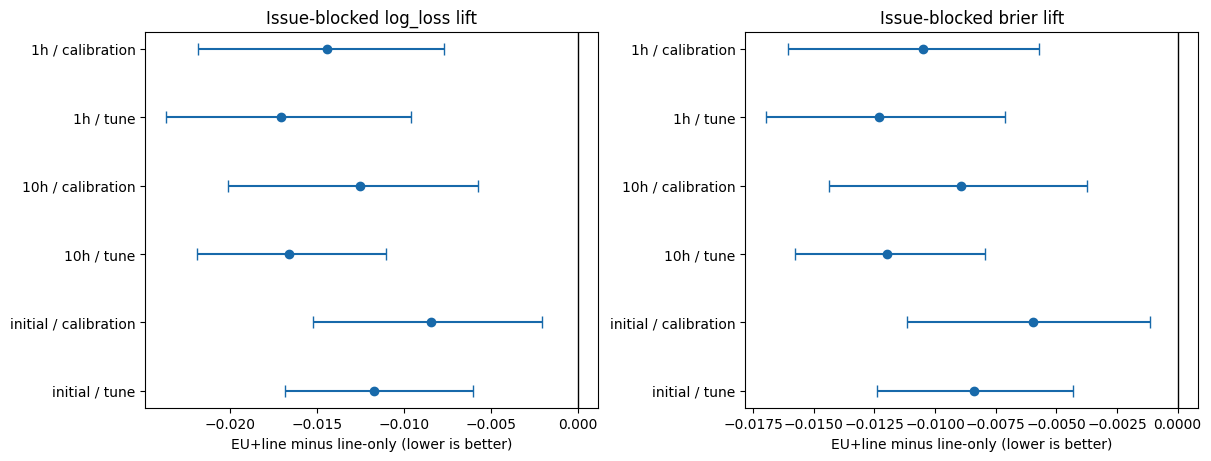

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for axis, metric in zip(axes, ['log_loss', 'brier']):
    view = bootstrap.loc[bootstrap.metric.eq(metric)].reset_index(drop=True)
    labels = view.horizon + ' / ' + view.temporal_role
    y = np.arange(len(view))
    axis.errorbar(view.experimental_minus_control, y,
                  xerr=[view.experimental_minus_control - view.ci_low,
                        view.ci_high - view.experimental_minus_control],
                  fmt='o', capsize=4, color='#1769aa')
    axis.axvline(0, color='black', linewidth=1)
    axis.set_yticks(y, labels)
    axis.set_title(f'Issue-blocked {metric} lift')
    axis.set_xlabel('EU+line minus line-only (lower is better)')
fig.savefig(FIGURES / 'bj238_mapping_lift.png', dpi=170)
plt.show()

## Issue-level capacity and disagreement surface

`eu_vs_line_divergence` compares the accepted event-specific European-plus-line mapping against the coarse line-only prior. It is a candidate feature, not a de-vigged Beijing SP probability and not evidence of betting profitability.

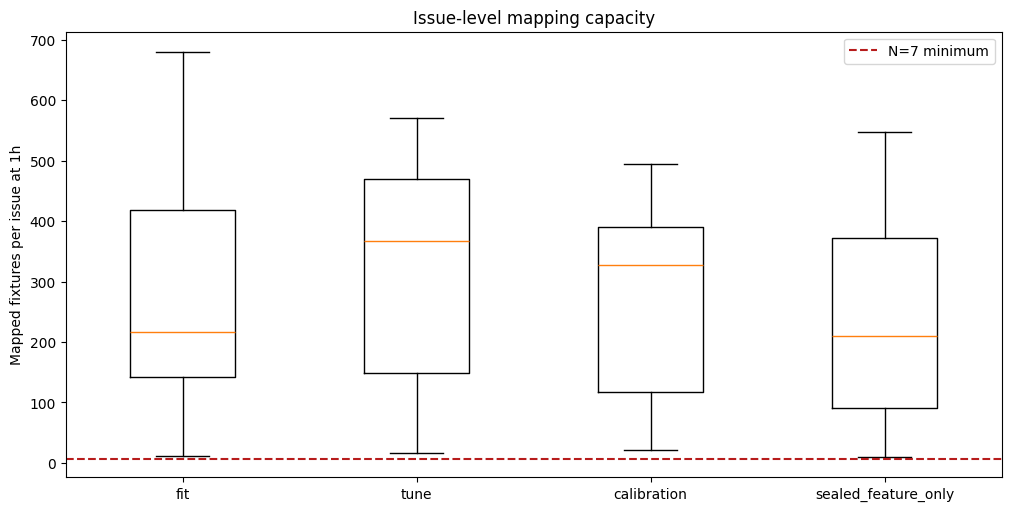

,temporal_role,snapshot_kind,native_handicap_line,outcome_code,cells,mean,mean_abs,q10,median,q90
26,calibration,1h,-2.0,0,646,-0.04352,0.07742,-0.15410,-0.04832,0.06672
35,calibration,1h,1.0,0,1431,-0.00003,0.07236,-0.10347,-0.01375,0.12482
24,calibration,1h,-2.0,3,646,0.04071,0.07115,-0.05973,0.03920,0.14778
33,calibration,1h,1.0,3,1431,0.00578,0.07015,-0.10701,0.01102,0.11289
27,calibration,1h,-1.0,3,3378,0.02303,0.06939,-0.08078,0.01166,0.13878
29,calibration,1h,-1.0,0,3378,-0.01584,0.06778,-0.12594,-0.01505,0.08918
39,calibration,1h,3.0,3,10,0.05189,0.06446,-0.02313,0.03269,0.16474
30,calibration,1h,0.0,3,8967,0.00712,0.06331,-0.09414,0.00910,0.10601
32,calibration,1h,0.0,0,8967,-0.00048,0.06056,-0.09182,-0.00974,0.10043
36,calibration,1h,2.0,3,203,-0.02099,0.05640,-0.09951,-0.02028,0.06580


In [5]:
order = ['fit', 'tune', 'calibration', 'sealed_feature_only']
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
groups = [capacity.loc[(capacity.temporal_role.eq(role)) & capacity.snapshot_kind.eq('1h'),
                       'available_fixtures'].to_numpy() for role in order]
ax.boxplot(groups, tick_labels=order, showfliers=False)
ax.axhline(7, color='#b71c1c', linestyle='--', label='N=7 minimum')
ax.set_ylabel('Mapped fixtures per issue at 1h')
ax.set_title('Issue-level mapping capacity')
ax.legend()
fig.savefig(FIGURES / 'bj238_issue_capacity.png', dpi=170)
plt.show()
calibration_1h = divergence.query("temporal_role == 'calibration' and snapshot_kind == '1h'")
display(calibration_1h.sort_values('mean_abs', ascending=False).head(18).round(5))

## Decision

All three relative horizons pass the preregistered chronological translator gate, so the package disposition is **READY_FOR_209_PI_MODELABILITY_REVIEW**. This is a positive probability-translation result, not a positive-EV result. #209 may consume the line-only prior, accepted EU-plus-line probability, and their per-cell divergence as separate features. Actual Beijing three-way pre-event SP probability remains unavailable in this historical lane, and 2024+ must remain sealed until the #209 method is frozen.